# clustering-classification-integrated-pipeline

## Group Members
- Member 1: Anshu
- Member 2: Aryan

## Project Objective
The objective of this project is to develop an integrated machine-learning pipeline where clustering is used before supervised classification.

First, K-Means clustering will group similar tumour samples based on their medical measurements. Then, the cluster information will be combined with the original features and used by a classification model to predict whether a tumuor is benign or malignant.

This project also compares the integrated model with a baseline classifier that uses the original features.

## Step 1: Import Required Libraries
The following libraries are used in this project:

- **pandas**:to organize and inspect data in table form. 
- **numpy**:to work with numerical arrays.
- **matplotlib**and**seanorn**:to create graphs and visualizations.
- **scikit-learn**:to load the dataset and build machine-learning models.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

# Makes the graphs look cleaner
sns.set_style("whitegrid")

## Step 2: Loading the Dataset
This project uses the Breast Cnacer Wisconsin Diagnostic dataset, which is available directly in scikit-learn.
The dataset contains medical measurements of cell nuclei taken from breast mass images. The target variable represents the diagnosis:
- '0' = Malignant
- '1' = Benign

In [3]:
# Load the built-in breast cancer dataset
data = load_breast_cancer()

# Store features and target labels separately
X = data.data
y = data.target

# Display basic information about the dataset
print("Number of records:", X.shape[0])
print("Number of features:", X.shape[1])
print("Feature names:")
print(data.feature_names)

print("\nTarget names:")
print(data.target_names)

Number of records: 569
Number of features: 30
Feature names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']

Target names:
['malignant' 'benign']


## Step 3: Creating a Data Table
The dataset is initially stored as numerical arrays. to make it easier to read and analyze, we convert the features into a pandas Dataframes.

Each row represents one patient sample, and each column represents one medical measurement, such as radius, texture, perimeter, or area.

In [4]:
# Convert the feature data into a DataFrame
df = pd.DataFrame(X, columns=data.feature_names)

# Add the diagnosis column
df["diagnosis"] = y

# Show the first five records
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## Step 4: Exploring the Dataset
Before training any machine learning model, it is important to understand the data setructure and check its quality. 

In this step, we will check:
- Dataset dimensions
- Column data types
- Missing values 
- Number of benign and malignant samples

In [5]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names and data types
df.info()

Dataset shape: (569, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  s

In [6]:
# Check for missing values in every column
missing_values = df.isnull().sum()

print("Missing values in the dataset:")
print(missing_values)

Missing values in the dataset:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
diagnosis                  0
dtype: int64


## Step 5: Checking Class Distribution
The target variable is the diagnosis:
- '0' represents malignant tumours.
- '1' represents benign tumours.

Checking the number of samoles in each class helps us understand whether the dataset is balanced or imbalanced.

Class distribution:
diagnosis
1    357
0    212
Name: count, dtype: int64


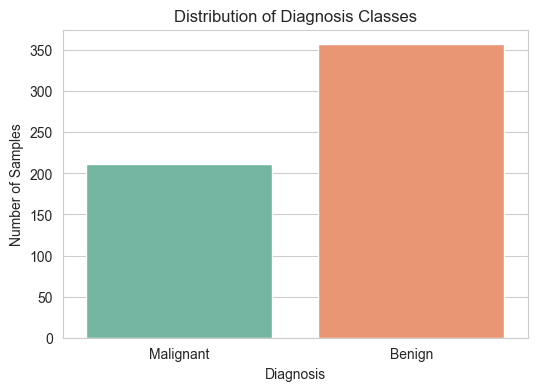

In [7]:
# Count samples in each diagnosis class
class_counts = df["diagnosis"].value_counts()

print("Class distribution:")
print(class_counts)

# Create readable labels for the chart
diagnosis_labels = df["diagnosis"].map({
    0: "Malignant",
    1: "Benign"
})

# Visualize the class distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=diagnosis_labels, hue=diagnosis_labels, palette="Set2", legend=False)

plt.title("Distribution of Diagnosis Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.show()

## Step 6: Splitting Features and Target 
For machine learning, we separate the dataset into:
- **Features('X')**: the 20 medical measurements used as input.
- **Target('y')**: the diagnosis label to be predicted.

Although K-Means clustering does not use the diagnosis label, we keep the target values for later analysis and for the classificaton stage.

In [8]:
# Features: remove the diagnosis column
X = df.drop("diagnosis", axis=1)

# Target: diagnosis column
y = df["diagnosis"]

print("Feature data shape:", X.shape)
print("Target data shape:", y.shape)

Feature data shape: (569, 30)
Target data shape: (569,)


## Step 7: Splitting Training and Testing Data
The dataset is divided into training and testing sets.
- The **testing set** is used to learn the scaling values and identify clusters.
- The **testing set** is kept seperate for Member 2 to evaluate the final classification model fairly.

A stratifiedd split keeps the proportion of benign and malignant cases similar in both sets.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split data: 75% for training and 25% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (426, 30)
Testing data shape: (143, 30)


## Feature Scaling 
The feature values have very different ranges. For example, area values are much larger than smoothness values.

K-Means relies on distance calculations, so features with larger values could dominate the clustering result. We therefore use StandardScaler to transform each feature to a similar scale.

The scaler is fitted only on training data to avoid data leakage.

In [10]:
# Create the scaler
scaler = StandardScaler()

# Learn scaling values from training data, then transform it
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling values to test data
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)


Scaled training data shape: (426, 30)
Scaled testing data shape: (143, 30)


## Step 9: Choosing the number of clusters
K-Means requires us to choose the number of clusters, represented by 'K'.

We use the **elbow method**. It calculates the within-cluster sum of squares (inertia) for different values of K.

A lower inertia is better, but it always decreases when more clusters are added. Therefore, wee select the point where the decrease starts becoming smaller, creating an "elbow" in the graph.

In [11]:
from sklearn.cluster import KMeans

# Store inertia values for different numbers of clusters
inertia_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_train_scaled)
    inertia_values.append(kmeans.inertia_)

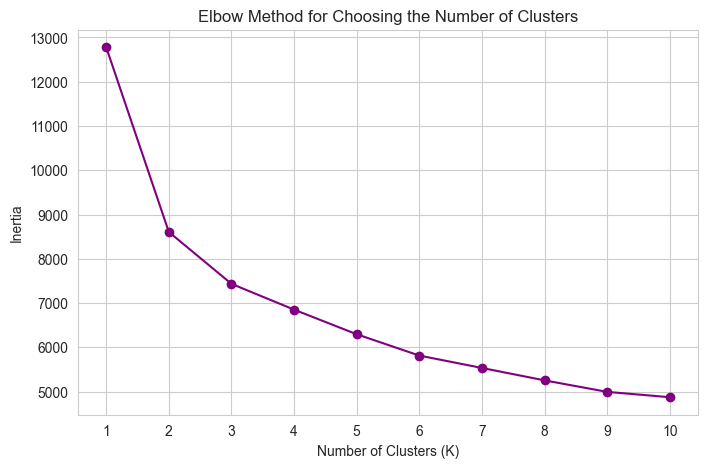

In [12]:
# Plot the elbow graph
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia_values, marker="o", color="purple")

plt.title("Elbow Method for Choosing the Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.show()

### Interpretation of the Elbow Method

The elbow graph shows how inertia changes as the number of clusters increases.

For this project, we will use **3 clusters**. This gives a useful grouping of
similar tumour samples while still keeping the clustering result simple enough
to interpret.

The clusters are created without using the benign/malignant diagnosis labels.
They represent patterns found naturally from the medical measurements.

## Step 10: Applying K-Means Clustering
Based on the elbow-method analysis, K-Means is applied with 'K=3'.

The model is trained only on the scaled training data. Each training record is assigned a cluster label: '0', '1', or '2'.

These labels do not mean malignant or benign. They only identify groups of samples that are similar according to their medical measurements.

In [13]:
# Create and train the K-Means model with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Assign a cluster label to every training record
train_clusters = kmeans.fit_predict(X_train_scaled)

# Predict cluster labels for test data using the trained K-Means model
test_clusters = kmeans.predict(X_test_scaled)

print("Cluster labels for training data:")
print(train_clusters[:10])

Cluster labels for training data:
[1 0 1 1 1 0 2 1 1 0]


## Step 11: Cluster Distribution

This step counts how many training samples belong to each cluster.

A reasonable distribution indicates that K-Means has formed meaningful groups
instead of putting almost all samples into only one cluster.

Number of samples in each cluster:
0    269
1     86
2     71
Name: count, dtype: int64


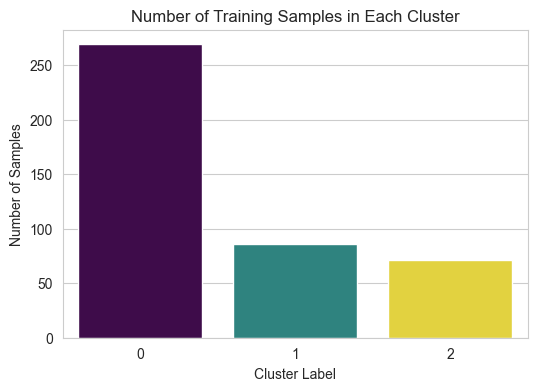

In [14]:
# Count samples in each cluster
cluster_counts = pd.Series(train_clusters).value_counts().sort_index()

print("Number of samples in each cluster:")
print(cluster_counts)

# Visualize cluster sizes
plt.figure(figsize=(6, 4))

sns.countplot(x=train_clusters, hue=train_clusters, palette="viridis", legend=False)

plt.title("Number of Training Samples in Each Cluster")
plt.xlabel("Cluster Label")
plt.ylabel("Number of Samples")
plt.show()

## Step 12: Visualizing Clusters Using PCA

The dataset contains 30 features, so it cannot be directly plotted on a
two-dimensional graph.

Principal Component Analysis (PCA) reduces the 30 scaled features to two
components for visualization. The plot helps us see how K-Means has grouped
similar samples.

PCA is used only for visualization; the actual clustering uses all 30 scaled
features.

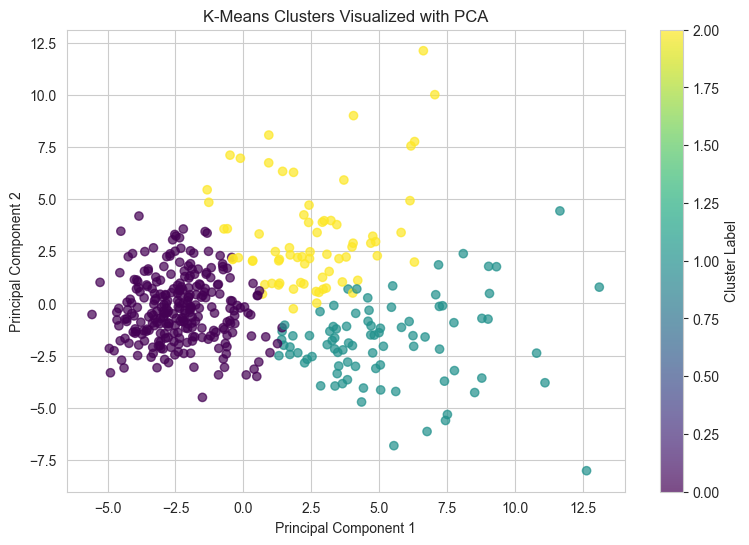

In [15]:
from sklearn.decomposition import PCA

# Reduce the training data to two dimensions for visualization
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

# Create a scatter plot of the clusters
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=train_clusters,
    cmap="viridis",
    alpha=0.7
)

plt.title("K-Means Clusters Visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster Label")
plt.show()

## Step 13: Comparing Clusters with Actual Diagnoses

K-Means clustering is unsupervised, so it does not use the diagnosis labels
when creating groups.

After clustering is complete, we can compare cluster labels with the known
diagnoses to understand whether certain clusters contain more benign or
malignant samples.

This is only an interpretation step. It is not used to train K-Means.

In [16]:
# Create a table to compare K-Means clusters with actual diagnoses
cluster_diagnosis_table = pd.crosstab(
    train_clusters,
    y_train.map({0: "Malignant", 1: "Benign"})
)

print(cluster_diagnosis_table)

diagnosis  Benign  Malignant
row_0                       
0             242         27
1               0         86
2              25         46


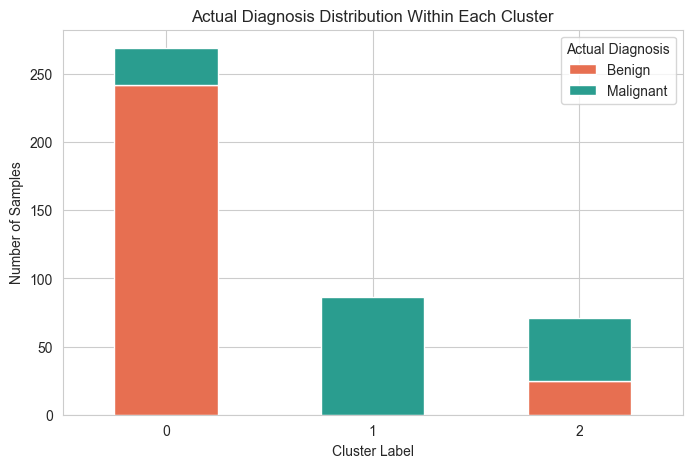

In [17]:
# Visualize the diagnosis distribution within each cluster
cluster_diagnosis_table.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#e76f51", "#2a9d8f"]
)

plt.title("Actual Diagnosis Distribution Within Each Cluster")
plt.xlabel("Cluster Label")
plt.ylabel("Number of Samples")
plt.legend(title="Actual Diagnosis")
plt.xticks(rotation=0)
plt.show()

## Member 1 Conclusion

The dataset was successfully loaded, explored, and preprocessed.

The features were standardized because K-Means is sensitive to differences in
feature scale. The elbow method was used to select three clusters, and K-Means
grouped similar tumour samples using all 30 medical measurements.

PCA was used to visualize the clusters in two dimensions. The comparison with
actual diagnoses shows whether clusters contain different proportions of
benign and malignant samples.

The scaled data and cluster labels are now ready for Member 2, who will build
a baseline classifier and an integrated classification model using cluster
information.